# 01. Exploratory Data Analysis (EDA)
Guideline sections **II (Description of the dataset)** and **III (Exploratory Data Analysis)**.

In this notebook we:
1. describe the source and the dimensionality of the dataset,
2. explain every feature (meaning, data type, number of distinct values, example values),
3. give descriptive statistics for **every** attribute (numerical and categorical),
4. inspect the target variable and missing values,
5. build ten charts of the features that matter most for cancellations.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

output_dir = '../results/01_data_exploration' if os.path.exists('../results') else 'results/01_data_exploration'
os.makedirs(output_dir, exist_ok=True)

data_path = '../data/raw/hotel_bookings.csv' if os.path.exists('../data/raw') else 'data/raw/hotel_bookings.csv'
df = pd.read_csv(data_path)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 1. Source of the dataset
* **Name:** Hotel Booking Demand (file `hotel_bookings.csv`).
* **Origin:** Antonio, N., de Almeida, A. & Nunes, L. (2019). *Hotel booking demand datasets*. **Data in Brief, 22, 41-49.** The authors extracted the data from the Property Management Systems (PMS) of two real hotels in Portugal: a **Resort Hotel** (Algarve) and a **City Hotel** (Lisbon). Personal information was removed.
* **Distribution:** made public on Kaggle (*jessemostipak/hotel-booking-demand*, TidyTuesday 2020).
* **Period:** bookings with arrival dates between **1 July 2015 and 31 August 2017**.
* **Why it suits our problem:** every row is one real booking and the column `is_canceled` tells whether it was cancelled. It also stores what the hotel knows when the booking is made (lead time, deposit, channel, price, special requests ...), so we can learn the cancellation pattern from information that is available *before* the guest arrives - exactly what a supervised classification model needs. With ~119k labelled rows it is big enough to train and fairly compare six algorithms.

## 2. Dimensionality of the dataset

In [2]:
n_rows, n_cols = df.shape
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(exclude='number').columns.tolist()

dim = pd.DataFrame({
    'Item': ['Rows (bookings)', 'Columns (attributes)', 'Numerical columns', 'Categorical / text columns',
             'Target column', 'Memory usage (MB)', 'Exact duplicate rows', 'First arrival', 'Last arrival'],
    'Value': [f'{n_rows:,}', n_cols, len(num_cols), len(cat_cols), 'is_canceled',
              round(df.memory_usage(deep=True).sum() / 1e6, 1), f'{df.duplicated().sum():,}',
              f"{df.arrival_date_year.min()}-{df.loc[df.arrival_date_year == df.arrival_date_year.min(), 'arrival_date_month'].iloc[0]}",
              f"{df.arrival_date_year.max()}-{df.loc[df.arrival_date_year == df.arrival_date_year.max(), 'arrival_date_month'].iloc[-1]}"]
})
dim.to_csv(f'{output_dir}/dataset_dimensionality.csv', index=False)
print(f'Dataset Dimensions: {n_rows:,} rows and {n_cols} columns')
dim

Dataset Dimensions: 119,390 rows and 32 columns


,Item,Value
0,Rows (bookings),"119,390"
1,Columns (attributes),32
2,Numerical columns,20
3,Categorical / text columns,12
4,Target column,is_canceled
5,Memory usage (MB),39.7
6,Exact duplicate rows,"31,994"
7,First arrival,2015-July
8,Last arrival,2017-August


## 3. Meaning and data type of every feature
The table below lists all 32 attributes: what they represent, their pandas data type, whether we treat them as numerical or categorical, the number of distinct values and some example values.

In [3]:
meaning = {
    'hotel': 'Hotel type: City Hotel or Resort Hotel',
    'is_canceled': 'TARGET - 1 if the booking was cancelled, 0 if the guest arrived',
    'lead_time': 'Days between the booking date and the arrival date',
    'arrival_date_year': 'Year of arrival (2015-2017)',
    'arrival_date_month': 'Month of arrival (January ... December)',
    'arrival_date_week_number': 'Week number of the year of arrival (1-53)',
    'arrival_date_day_of_month': 'Day of the month of arrival (1-31)',
    'stays_in_weekend_nights': 'Number of weekend nights (Saturday/Sunday) booked',
    'stays_in_week_nights': 'Number of week nights (Monday-Friday) booked',
    'adults': 'Number of adults',
    'children': 'Number of children',
    'babies': 'Number of babies',
    'meal': 'Meal package: BB (bed & breakfast), HB (half board), FB (full board), SC/Undefined (no meal)',
    'country': 'Country of origin of the guest (ISO 3166-1 alpha-3 code)',
    'market_segment': 'Market segment (Online TA, Offline TA/TO, Groups, Direct, Corporate, ...)',
    'distribution_channel': 'Booking distribution channel (TA/TO = travel agents/tour operators, Direct, Corporate, GDS)',
    'is_repeated_guest': '1 if the guest has stayed at the hotel before, else 0',
    'previous_cancellations': 'Number of earlier bookings of this guest that were cancelled',
    'previous_bookings_not_canceled': 'Number of earlier bookings of this guest that were not cancelled',
    'reserved_room_type': 'Code of the room type reserved (A-L, anonymised)',
    'assigned_room_type': 'Code of the room type actually assigned (can differ from the reserved one)',
    'booking_changes': 'Number of changes made to the booking until check-in or cancellation',
    'deposit_type': 'No Deposit, Non Refund (full prepayment) or Refundable deposit',
    'agent': 'ID of the travel agency that made the booking (anonymised, NaN = no agency)',
    'company': 'ID of the company that pays for the booking (anonymised, NaN = no company)',
    'days_in_waiting_list': 'Days the booking waited on the waiting list before it was confirmed',
    'customer_type': 'Transient, Transient-Party, Contract or Group',
    'adr': 'Average Daily Rate in EUR = total lodging price / number of nights',
    'required_car_parking_spaces': 'Number of car parking spaces requested',
    'total_of_special_requests': 'Number of special requests (e.g. twin bed, high floor)',
    'reservation_status': 'Final status: Check-Out, Canceled or No-Show (only known AFTER the outcome)',
    'reservation_status_date': 'Date the last status was set (only known AFTER the outcome)',
}
binary = {'is_canceled', 'is_repeated_guest'}
rows = []
for c in df.columns:
    s = df[c]
    kind = 'Target (binary)' if c == 'is_canceled' else (
        'Binary' if c in binary else ('Numerical' if pd.api.types.is_numeric_dtype(s) else 'Categorical'))
    if c in ('agent', 'company'):
        kind = 'Categorical ID (stored as number)'
    if c == 'reservation_status_date':
        kind = 'Date (text)'
    ex = ', '.join(map(str, s.dropna().unique()[:4]))
    rows.append({'Feature': c, 'Meaning': meaning[c], 'Data type': str(s.dtype), 'Kind': kind,
                 'Distinct values': s.nunique(), 'Example values': ex})
feature_dictionary = pd.DataFrame(rows)
feature_dictionary.to_csv(f'{output_dir}/feature_dictionary.csv', index=False)
with pd.option_context('display.max_colwidth', 70):
    display(feature_dictionary)

,Feature,Meaning,Data type,Kind,Distinct values,Example values
0,hotel,Hotel type: City Hotel or Resort Hotel,str,Categorical,2,"Resort Hotel, City Hotel"
1,is_canceled,"TARGET - 1 if the booking was cancelled, 0 if the guest arrived",int64,Target (binary),2,"0, 1"
2,lead_time,Days between the booking date and the arrival date,int64,Numerical,479,"342, 737, 7, 13"
3,arrival_date_year,Year of arrival (2015-2017),int64,Numerical,3,"2015, 2016, 2017"
4,arrival_date_month,Month of arrival (January ... December),str,Categorical,12,"July, August, September, October"
5,arrival_date_week_number,Week number of the year of arrival (1-53),int64,Numerical,53,"27, 28, 29, 30"
6,arrival_date_day_of_month,Day of the month of arrival (1-31),int64,Numerical,31,"1, 2, 3, 4"
7,stays_in_weekend_nights,Number of weekend nights (Saturday/Sunday) booked,int64,Numerical,17,"0, 1, 2, 4"
8,stays_in_week_nights,Number of week nights (Monday-Friday) booked,int64,Numerical,35,"0, 1, 2, 3"
9,adults,Number of adults,int64,Numerical,14,"2, 1, 3, 4"


**Note on leakage columns:** `reservation_status` and `reservation_status_date` are only filled in *after* the guest arrives or cancels (`Canceled` / `No-Show` = cancelled). They describe the answer, not the booking, so they are removed in preprocessing (notebook 02).

## 4. Descriptive statistics for every attribute
### 4.1 Numerical attributes

In [4]:
num = df.select_dtypes(include='number')
desc_num = num.describe().T
desc_num['median'] = num.median()
desc_num['skewness'] = num.skew()
desc_num['kurtosis'] = num.kurt()
desc_num['missing'] = num.isnull().sum()
desc_num = desc_num[['count', 'missing', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'skewness', 'kurtosis']]
desc_num.round(3).to_csv(f'{output_dir}/descriptive_statistics_numerical.csv')
desc_num.round(2)

,count,missing,mean,std,min,25%,median,75%,max,skewness,kurtosis
is_canceled,119390.0,0,0.37,0.48,0.00,0.00,0.00,1.0,1.0,0.54,-1.71
lead_time,119390.0,0,104.01,106.86,0.00,18.00,69.00,160.0,737.0,1.35,1.70
arrival_date_year,119390.0,0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0,-0.23,-0.99
arrival_date_week_number,119390.0,0,27.17,13.61,1.00,16.00,28.00,38.0,53.0,-0.01,-0.99
arrival_date_day_of_month,119390.0,0,15.80,8.78,1.00,8.00,16.00,23.0,31.0,-0.00,-1.19
stays_in_weekend_nights,119390.0,0,0.93,1.00,0.00,0.00,1.00,2.0,19.0,1.38,7.17
stays_in_week_nights,119390.0,0,2.50,1.91,0.00,1.00,2.00,3.0,50.0,2.86,24.28
adults,119390.0,0,1.86,0.58,0.00,2.00,2.00,2.0,55.0,18.32,1352.12
children,119386.0,4,0.10,0.40,0.00,0.00,0.00,0.0,10.0,4.11,18.67
babies,119390.0,0,0.01,0.10,0.00,0.00,0.00,0.0,10.0,24.65,1633.95


### 4.2 Categorical attributes

In [5]:
cat = df.select_dtypes(exclude='number')
desc_cat = cat.describe().T
desc_cat['top_share_%'] = (desc_cat['freq'] / len(df) * 100).astype(float).round(2)
desc_cat['missing'] = cat.isnull().sum()
desc_cat.to_csv(f'{output_dir}/descriptive_statistics_categorical.csv')
desc_cat

,count,unique,top,freq,top_share_%,missing
hotel,119390,2,City Hotel,79330,66.45,0
arrival_date_month,119390,12,August,13877,11.62,0
meal,119390,5,BB,92310,77.32,0
country,118902,177,PRT,48590,40.70,488
market_segment,119390,8,Online TA,56477,47.30,0
distribution_channel,119390,5,TA/TO,97870,81.98,0
reserved_room_type,119390,10,A,85994,72.03,0
assigned_room_type,119390,12,A,74053,62.03,0
deposit_type,119390,3,No Deposit,104641,87.65,0
customer_type,119390,4,Transient,89613,75.06,0


In [6]:
# Frequency tables of the low-cardinality categorical attributes
for c in ['hotel', 'meal', 'market_segment', 'distribution_channel', 'deposit_type', 'customer_type', 'reservation_status']:
    vc = df[c].value_counts()
    print(f'--- {c} ---')
    print(pd.DataFrame({'count': vc, 'share_%': (vc / len(df) * 100).round(2),
                        'cancel_rate_%': (df.groupby(c)['is_canceled'].mean()[vc.index] * 100).round(1)}).to_string(), '\n')

--- hotel ---
              count  share_%  cancel_rate_%
hotel                                      
City Hotel    79330    66.45           41.7
Resort Hotel  40060    33.55           27.8 

--- meal ---
           count  share_%  cancel_rate_%
meal                                    
BB         92310    77.32           37.4
HB         14463    12.11           34.5
SC         10650     8.92           37.2
Undefined   1169     0.98           24.5
FB           798     0.67           59.9 

--- market_segment ---
                count  share_%  cancel_rate_%
market_segment                               
Online TA       56477    47.30           36.7
Offline TA/TO   24219    20.29           34.3
Groups          19811    16.59           61.1
Direct          12606    10.56           15.3
Corporate        5295     4.44           18.7
Complementary     743     0.62           13.1
Aviation          237     0.20           21.9
Undefined           2     0.00          100.0 

--- distribution_chan

**Reading the statistics:**
* Most numerical attributes are strongly **right-skewed** (skewness > 1): `lead_time`, `adr`, `stays_in_week_nights`, `days_in_waiting_list`, `previous_cancellations`, `babies`. Their maximum values are far above the 75th percentile - these are the candidate outliers we analyse in notebook 02.
* `adr` has a minimum below zero and a maximum of 5,400 EUR, which are data-entry errors.
* `adults` has a minimum of 0 - bookings without any guest are not real stays.
* `agent` and `company` are numbers but they are **IDs**, so their mean has no meaning.

## 5. Target variable: booking cancellation rate

Completed Stays (0): 75,166 (63.0%)
Canceled Bookings (1): 44,224 (37.0%)


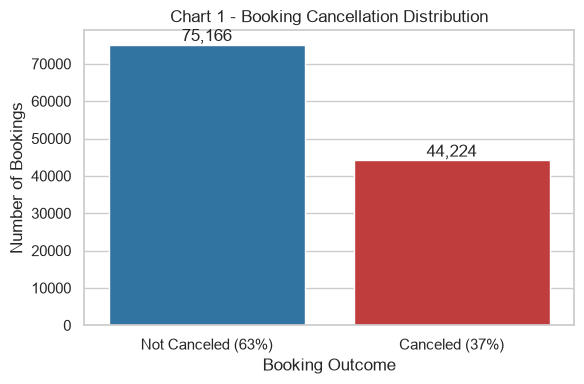

In [7]:
cancel_counts = df['is_canceled'].value_counts()
cancel_rate = df['is_canceled'].mean() * 100
print(f"Completed Stays (0): {cancel_counts[0]:,} ({100 - cancel_rate:.1f}%)")
print(f"Canceled Bookings (1): {cancel_counts[1]:,} ({cancel_rate:.1f}%)")

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='is_canceled', hue='is_canceled', palette=['#1f77b4', '#d62728'], legend=False)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
plt.title('Chart 1 - Booking Cancellation Distribution')
plt.xlabel('Booking Outcome')
plt.ylabel('Number of Bookings')
plt.xticks([0, 1], [f'Not Canceled ({100 - cancel_rate:.0f}%)', f'Canceled ({cancel_rate:.0f}%)'])
plt.tight_layout()
plt.savefig(f'{output_dir}/target_distribution.png', dpi=300)
plt.show()

The classes are **moderately imbalanced (63 / 37)**. Accuracy alone can therefore be misleading, so we also report precision, recall, F1-score and ROC-AUC, and we use a **stratified** train/test split.

## 6. Missing values (first look - handled in notebook 02)

In [8]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_df = pd.DataFrame({'Missing_Rows': missing, 'Percentage': (missing / len(df) * 100).round(2)})
missing_df.to_csv(f'{output_dir}/missing_values_summary.csv')
print('Missing Values:')
missing_df

Missing Values:


,Missing_Rows,Percentage
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


## 7. Charts of the most important features
### Chart 2 - Cancellation rate by hotel type, deposit type and market segment

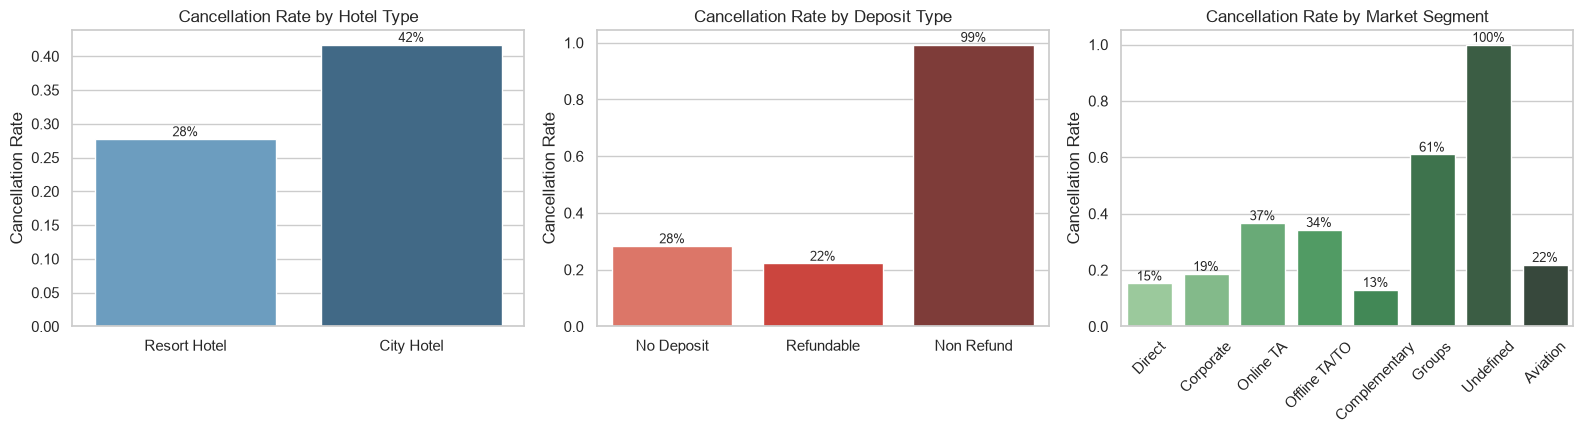

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, pal, title in zip(axes, ['hotel', 'deposit_type', 'market_segment'], ['Blues_d', 'Reds_d', 'Greens_d'],
                               ['Hotel Type', 'Deposit Type', 'Market Segment']):
    sns.barplot(data=df, x=col, y='is_canceled', hue=col, ax=ax, palette=pal, legend=False, errorbar=None)
    ax.set_title(f'Cancellation Rate by {title}')
    ax.set_ylabel('Cancellation Rate')
    ax.set_xlabel('')
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.0%}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=9)
axes[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(f'{output_dir}/cancellation_by_categories.png', dpi=300)
plt.show()

### Chart 3 - Lead time and price (ADR) by cancellation status

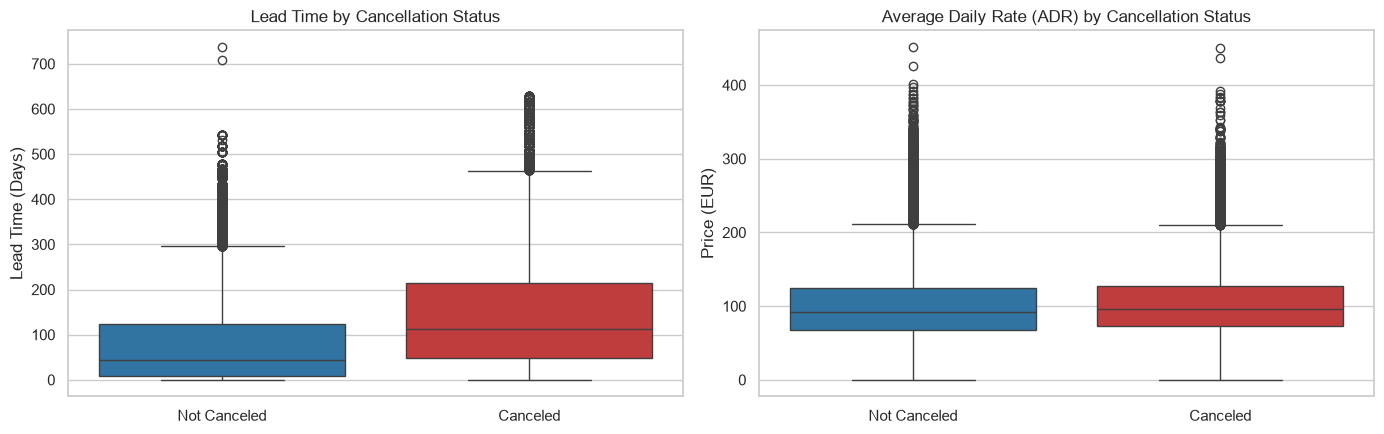

Median Values by Booking Status:
             lead_time   adr
is_canceled                 
0                 45.0  92.5
1                113.0  96.2


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x='is_canceled', y='lead_time', hue='is_canceled', ax=axes[0], palette=['#1f77b4', '#d62728'], legend=False)
axes[0].set_title('Lead Time by Cancellation Status')
axes[0].set_xticks([0, 1], ['Not Canceled', 'Canceled'])
axes[0].set_ylabel('Lead Time (Days)')
axes[0].set_xlabel('')
sns.boxplot(data=df[(df['adr'] >= 0) & (df['adr'] < 500)], x='is_canceled', y='adr', hue='is_canceled', ax=axes[1],
            palette=['#1f77b4', '#d62728'], legend=False)
axes[1].set_title('Average Daily Rate (ADR) by Cancellation Status')
axes[1].set_xticks([0, 1], ['Not Canceled', 'Canceled'])
axes[1].set_ylabel('Price (EUR)')
axes[1].set_xlabel('')
plt.tight_layout()
plt.savefig(f'{output_dir}/lead_time_and_adr_boxplots.png', dpi=300)
plt.show()

summary_stats = df.groupby('is_canceled')[['lead_time', 'adr']].median()
summary_stats.to_csv(f'{output_dir}/lead_time_adr_medians.csv')
print('Median Values by Booking Status:')
print(summary_stats)

### Chart 4 - Distributions (histograms) of the main numerical features

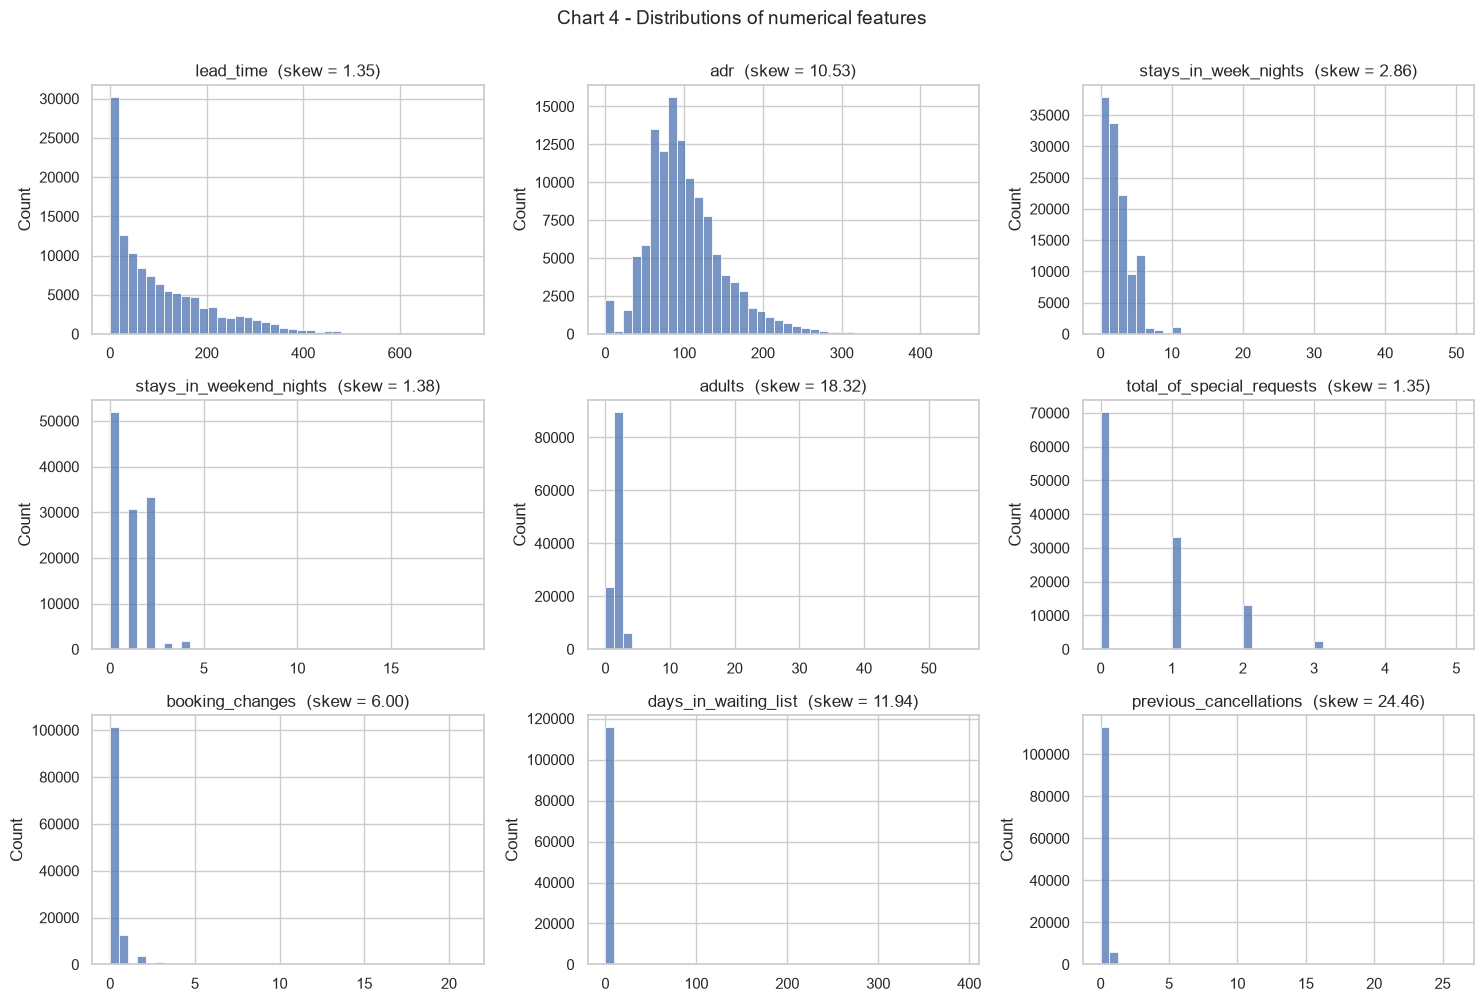

In [11]:
cols = ['lead_time', 'adr', 'stays_in_week_nights', 'stays_in_weekend_nights', 'adults',
        'total_of_special_requests', 'booking_changes', 'days_in_waiting_list', 'previous_cancellations']
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), cols):
    data = df[c] if c != 'adr' else df.loc[(df.adr >= 0) & (df.adr < 500), c]
    sns.histplot(data, bins=40, ax=ax, color='#4c72b0')
    ax.set_title(f'{c}  (skew = {df[c].skew():.2f})')
    ax.set_xlabel('')
plt.suptitle('Chart 4 - Distributions of numerical features', fontsize=14, y=1.0)
plt.tight_layout()
plt.savefig(f'{output_dir}/numerical_histograms.png', dpi=300)
plt.show()

### Chart 5 - Seasonality: bookings and cancellation rate per arrival month

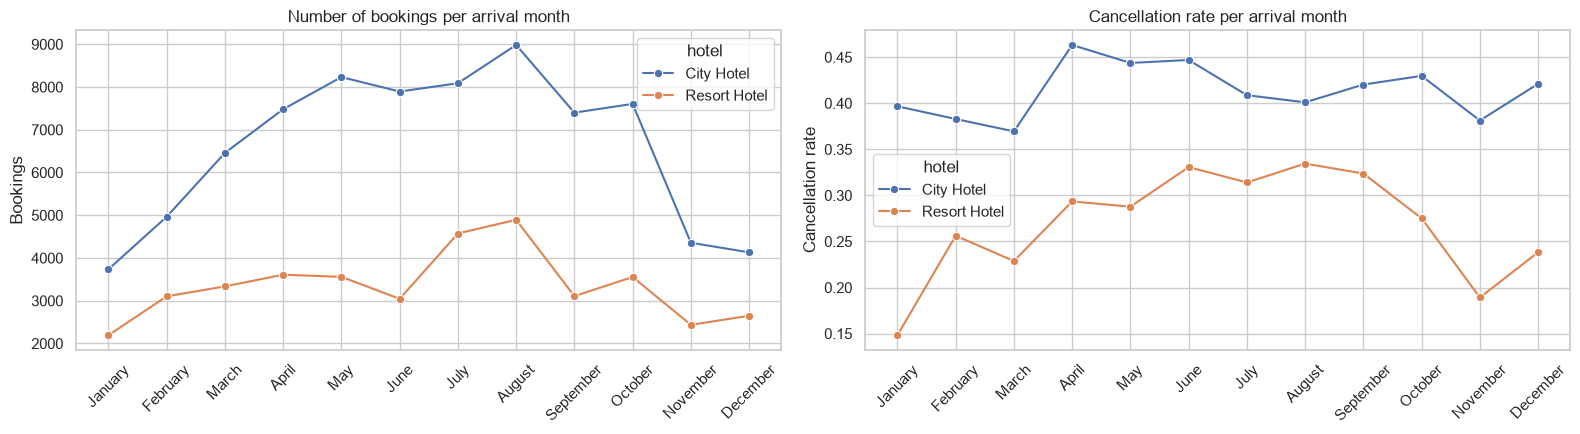

In [12]:
months = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
monthly = df.groupby(['arrival_date_month', 'hotel'])['is_canceled'].agg(['size', 'mean']).reset_index()
monthly['arrival_date_month'] = pd.Categorical(monthly['arrival_date_month'], months, ordered=True)
monthly = monthly.sort_values('arrival_date_month')

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.lineplot(data=monthly, x='arrival_date_month', y='size', hue='hotel', marker='o', ax=axes[0])
axes[0].set_title('Number of bookings per arrival month')
axes[0].set_ylabel('Bookings')
sns.lineplot(data=monthly, x='arrival_date_month', y='mean', hue='hotel', marker='o', ax=axes[1])
axes[1].set_title('Cancellation rate per arrival month')
axes[1].set_ylabel('Cancellation rate')
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
    ax.set_xlabel('')
plt.tight_layout()
plt.savefig(f'{output_dir}/monthly_seasonality.png', dpi=300)
plt.show()
monthly.to_csv(f'{output_dir}/monthly_bookings_cancel_rate.csv', index=False)

### Chart 6 - Correlation heatmap of numerical features

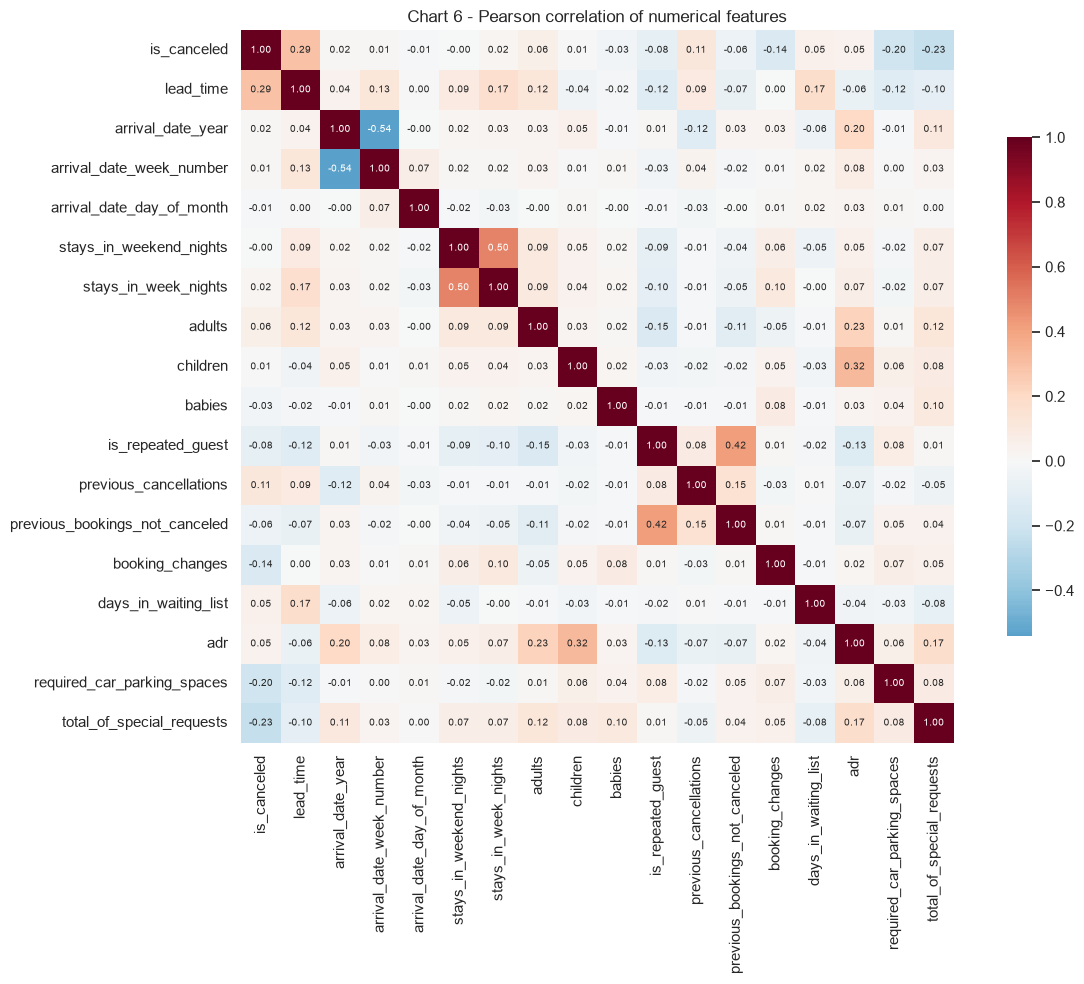

Correlation with is_canceled:
lead_time                         0.293
total_of_special_requests        -0.235
required_car_parking_spaces      -0.195
booking_changes                  -0.144
previous_cancellations            0.110
is_repeated_guest                -0.085
adults                            0.060
previous_bookings_not_canceled   -0.057
days_in_waiting_list              0.054
adr                               0.048
babies                           -0.032
stays_in_week_nights              0.025
arrival_date_year                 0.017
arrival_date_week_number          0.008
arrival_date_day_of_month        -0.006
children                          0.005
stays_in_weekend_nights          -0.002


In [13]:
corr = df.select_dtypes(include='number').drop(columns=['agent', 'company']).corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 7}, square=True, cbar_kws={'shrink': .7})
plt.title('Chart 6 - Pearson correlation of numerical features')
plt.tight_layout()
plt.savefig(f'{output_dir}/correlation_heatmap.png', dpi=300)
plt.show()

target_corr = corr['is_canceled'].drop('is_canceled').sort_values(key=abs, ascending=False)
target_corr.to_csv(f'{output_dir}/correlation_with_target.csv', header=['corr_with_is_canceled'])
print('Correlation with is_canceled:')
print(target_corr.round(3).to_string())

### Chart 7 - Top 10 countries: booking volume and cancellation rate

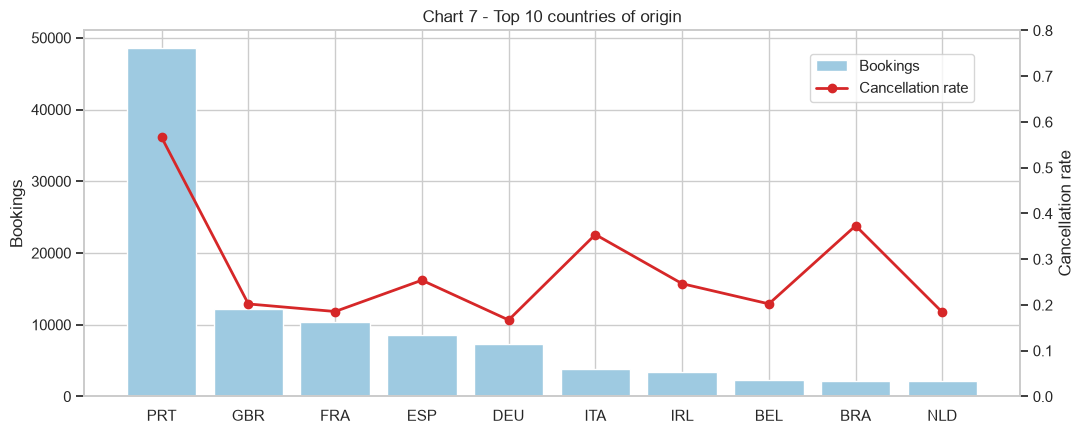

,bookings,cancel_rate
country,,
PRT,48590,0.566
GBR,12129,0.202
FRA,10415,0.186
ESP,8568,0.254
DEU,7287,0.167
ITA,3766,0.354
IRL,3375,0.247
BEL,2342,0.202
BRA,2224,0.373


In [14]:
top = df['country'].value_counts().head(10).index
cty = df[df['country'].isin(top)].groupby('country')['is_canceled'].agg(['size', 'mean']).loc[top]
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(cty.index, cty['size'], color='#9ecae1', label='Bookings')
ax1.set_ylabel('Bookings')
ax2 = ax1.twinx()
ax2.plot(cty.index, cty['mean'], color='#d62728', marker='o', lw=2, label='Cancellation rate')
ax2.set_ylabel('Cancellation rate')
ax2.set_ylim(0, 0.8)
ax2.grid(False)
ax1.set_title('Chart 7 - Top 10 countries of origin')
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.88))
plt.tight_layout()
plt.savefig(f'{output_dir}/top_countries.png', dpi=300)
plt.show()
cty.rename(columns={'size': 'bookings', 'mean': 'cancel_rate'}).round(3)

### Chart 8 - Commitment signals: special requests, parking, previous cancellations, booking changes

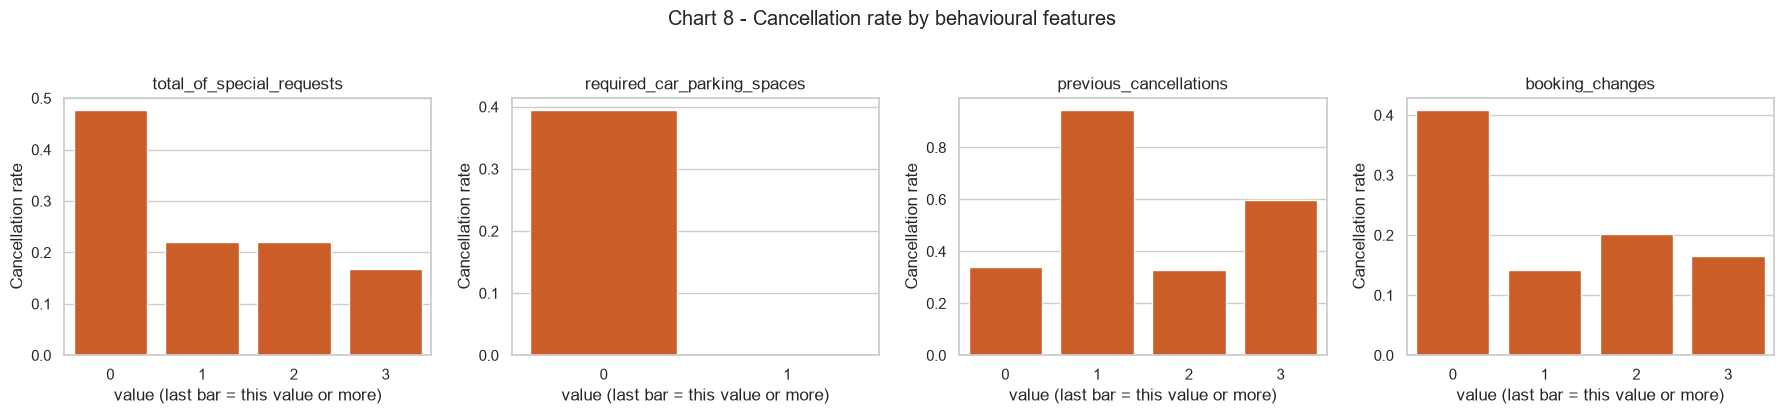

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ['total_of_special_requests', 'required_car_parking_spaces', 'previous_cancellations', 'booking_changes']):
    tmp = df[[c, 'is_canceled']].copy()
    tmp[c] = tmp[c].clip(upper=3 if c != 'required_car_parking_spaces' else 1)
    sns.barplot(data=tmp, x=c, y='is_canceled', ax=ax, color='#e6550d', errorbar=None)
    ax.set_title(c)
    ax.set_ylabel('Cancellation rate')
    ax.set_xlabel('value (last bar = this value or more)')
plt.suptitle('Chart 8 - Cancellation rate by behavioural features', y=1.03)
plt.tight_layout()
plt.savefig(f'{output_dir}/behavioural_features.png', dpi=300)
plt.show()

### Chart 9 - Customer type and distribution channel

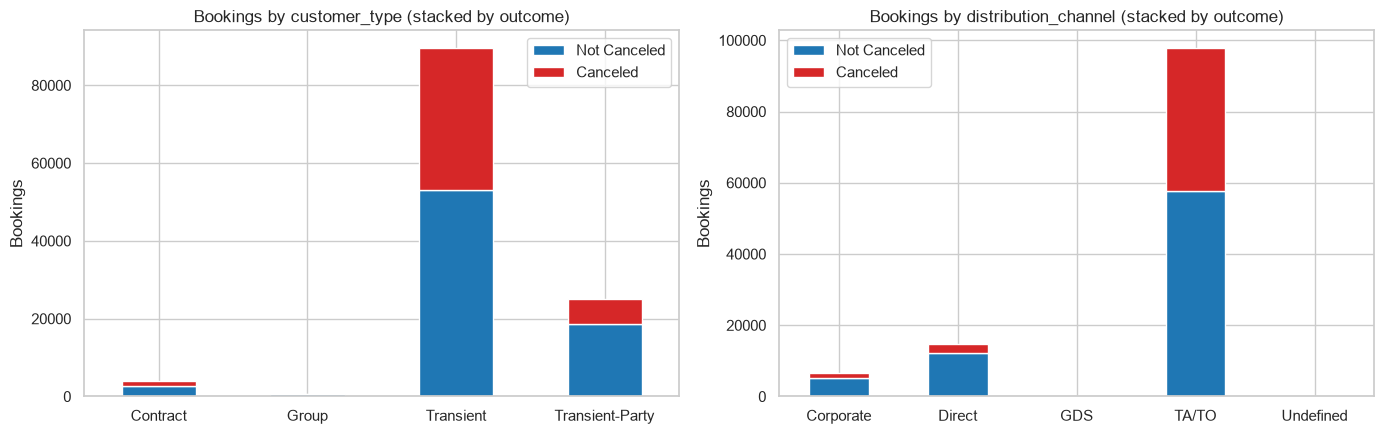

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, c in zip(axes, ['customer_type', 'distribution_channel']):
    ct = pd.crosstab(df[c], df['is_canceled'])
    ct.columns = ['Not Canceled', 'Canceled']
    ct.plot(kind='bar', stacked=True, ax=ax, color=['#1f77b4', '#d62728'])
    ax.set_title(f'Bookings by {c} (stacked by outcome)')
    ax.set_ylabel('Bookings')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig(f'{output_dir}/customer_type_channel.png', dpi=300)
plt.show()

### Chart 10 - Lead time density by outcome

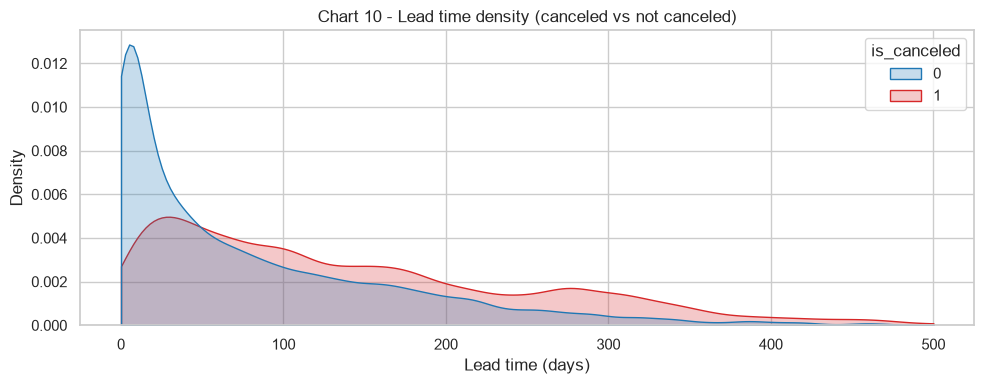

,bookings,cancel_rate
lead_time,,
0-7,19746,0.096
8-30,18960,0.279
31-90,29553,0.377
91-180,26439,0.447
181-365,21544,0.555
>365,3148,0.677


In [17]:
plt.figure(figsize=(10, 4))
sns.kdeplot(data=df, x='lead_time', hue='is_canceled', fill=True, common_norm=False, palette=['#1f77b4', '#d62728'], clip=(0, 500))
plt.title('Chart 10 - Lead time density (canceled vs not canceled)')
plt.xlabel('Lead time (days)')
plt.tight_layout()
plt.savefig(f'{output_dir}/lead_time_density.png', dpi=300)
plt.show()

bins = [-1, 7, 30, 90, 180, 365, 800]
labels = ['0-7', '8-30', '31-90', '91-180', '181-365', '>365']
lt = df.groupby(pd.cut(df['lead_time'], bins, labels=labels), observed=True)['is_canceled'].agg(['size', 'mean'])
lt.columns = ['bookings', 'cancel_rate']
lt.to_csv(f'{output_dir}/cancel_rate_by_lead_time_band.csv')
lt.round(3)

## 8. Key numbers used in the summary

In [18]:
facts = {
    'cancel_rate_%': round(df.is_canceled.mean() * 100, 1),
    'city_cancel_%': round(df[df.hotel == 'City Hotel'].is_canceled.mean() * 100, 1),
    'resort_cancel_%': round(df[df.hotel == 'Resort Hotel'].is_canceled.mean() * 100, 1),
    'non_refund_cancel_%': round(df[df.deposit_type == 'Non Refund'].is_canceled.mean() * 100, 1),
    'no_deposit_cancel_%': round(df[df.deposit_type == 'No Deposit'].is_canceled.mean() * 100, 1),
    'median_lead_cancel': df[df.is_canceled == 1].lead_time.median(),
    'median_lead_kept': df[df.is_canceled == 0].lead_time.median(),
    'cancel_%_0_requests': round(df[df.total_of_special_requests == 0].is_canceled.mean() * 100, 1),
    'cancel_%_parking': round(df[df.required_car_parking_spaces > 0].is_canceled.mean() * 100, 1),
    'PRT_cancel_%': round(df[df.country == 'PRT'].is_canceled.mean() * 100, 1),
    'PRT_share_%': round((df.country == 'PRT').mean() * 100, 1),
    'groups_cancel_%': round(df[df.market_segment == 'Groups'].is_canceled.mean() * 100, 1),
}
pd.Series(facts).to_csv(f'{output_dir}/eda_key_facts.csv', header=['value'])
pd.Series(facts)

cancel_rate_%           37.0
city_cancel_%           41.7
resort_cancel_%         27.8
non_refund_cancel_%     99.4
no_deposit_cancel_%     28.4
median_lead_cancel     113.0
median_lead_kept        45.0
cancel_%_0_requests     47.7
cancel_%_parking         0.0
PRT_cancel_%            56.6
PRT_share_%             40.7
groups_cancel_%         61.1
dtype: float64

## Summary of Exploration Findings
1. **Size:** 119,390 bookings x 32 attributes (20 numerical, 12 categorical/text); 31,994 rows are exact duplicates (common in PMS exports: several identical rooms booked together).
2. **Target:** 37.0% cancelled vs 63.0% not cancelled - moderately imbalanced, so we report F1, precision, recall and ROC-AUC besides accuracy.
3. **Hotel type:** the City Hotel cancels much more often (41.7%) than the Resort Hotel (27.8%).
4. **Deposit paradox:** 'Non Refund' bookings are cancelled 99.4% of the time (vs 28.4% for 'No Deposit'); 97% of them come from Portugal, 63% are Groups and their median lead time is 183 days (overall 69) - typical block bookings of tour operators that are later released.
5. **Lead time** is the strongest numerical signal (correlation +0.29): median 113 days for cancelled vs 45 days for kept bookings; the cancellation rate rises from 9.6% (0-7 days) to 67.7% (>1 year).
6. **Commitment signals lower the risk:** bookings with no special request cancel 47.7% of the time, those with requests ~22%; not a single booking that asked for a parking space was cancelled.
7. **Market segment / country:** Groups (61.1%) and guests from Portugal (56.6%, 40.7% of all bookings) cancel most; Direct and Corporate bookings least.
8. **Seasonality:** most bookings arrive in July-August; the cancellation rate is highest in spring/summer months.
9. **Missing values:** `company` (94.3%), `agent` (13.7%), `country` (0.41%) and `children` (4 rows) - handled in notebook 02.
10. **Leakage:** `reservation_status` maps 1-to-1 to the target and must be removed.